# Module 05 · Mạch op-amp chuyên dụng (Floyd chương 14)

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Mạch khuếch đại thiết bị: loại bỏ nhiễu chung

Av = 201;  Vout = 1.005 V  (common-mode 225 mV rejected)
RG for gain 1000: 200 ohm;  AD622 with 1k: 51.5


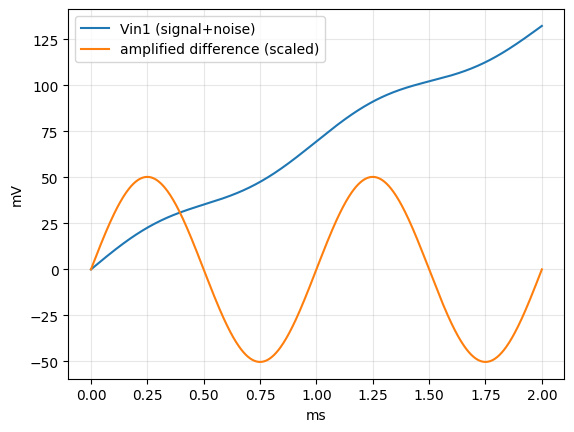

In [2]:
R, RG = 100e3, 1e3
Av = 1 + 2*R/RG
v1, v2, vcm = 5e-3, 10e-3, 225e-3
print(f"Av = {Av:.0f};  Vout = {Av*(v2-v1):.3f} V  (common-mode {vcm*1e3:.0f} mV rejected)")
print(f"RG for gain 1000: {2*R/999:.0f} ohm;  AD622 with 1k: {1+50.5e3/1e3:.1f}")
t = np.linspace(0, 2e-3, 800); sig = 5e-3*np.sin(2*np.pi*1e3*t); noise = 225e-3*np.sin(2*np.pi*50*t)
plt.plot(t*1e3, (sig+noise)*1e3, label="Vin1 (signal+noise)"); plt.plot(t*1e3, Av*sig*1e3/20, label="amplified difference (scaled)"); plt.legend(); plt.grid(alpha=.3); plt.xlabel("ms"); plt.ylabel("mV"); plt.show()

**Nhận xét:** Av = 201 và Vout = 1,005 V chỉ từ hiệu 5 mV; thành phần chung 225 mV hoàn toàn bị triệt. RG = 200 Ω cho độ lợi 1000 và AD622 với 1,0 kΩ cho 51,5 — đều trùng đáp án sách.

## 2. Băng thông giảm khi độ lợi tăng

In [3]:
fT = 8e6   # AD622: 800 kHz at gain 10 -> gain-bandwidth ~ 8 MHz
for G in (1, 10, 100, 1000): print(f"G = {G:>4}: BW ~ {fT/G/1e3:,.0f} kHz")

G =    1: BW ~ 8,000 kHz
G =   10: BW ~ 800 kHz
G =  100: BW ~ 80 kHz
G = 1000: BW ~ 8 kHz


**Nhận xét:** Với tích độ lợi–băng thông xấp xỉ 8 MHz (800 kHz tại G = 10 theo Floyd), G = 1000 chỉ còn khoảng 8 kHz.

## 3. OTA

In [4]:
gm, Vin, RL = 5000e-6, 0.1, 10e3
Io = gm*Vin; print(f"Iout = {Io*1e6:.0f} uA, Vout = {Io*RL:.1f} V, Av = {gm*RL:.0f}")
for ib in (25, 50, 100, 200): print(f"IBIAS = {ib:>3} uA -> gm = {16*ib} uS -> Av(RL=10k) = {16*ib*1e-6*10e3:.1f}")

Iout = 500 uA, Vout = 5.0 V, Av = 50
IBIAS =  25 uA -> gm = 400 uS -> Av(RL=10k) = 4.0
IBIAS =  50 uA -> gm = 800 uS -> Av(RL=10k) = 8.0
IBIAS = 100 uA -> gm = 1600 uS -> Av(RL=10k) = 16.0
IBIAS = 200 uA -> gm = 3200 uS -> Av(RL=10k) = 32.0


**Nhận xét:** Iout = 500 μA, Vout = 5 V (đúng sách). Gấp đôi dòng phân cực thì gấp đôi gm và độ lợi.

## 4. Mạch logarit

Prob 27: -157 mV;  Prob 26: -148 mV


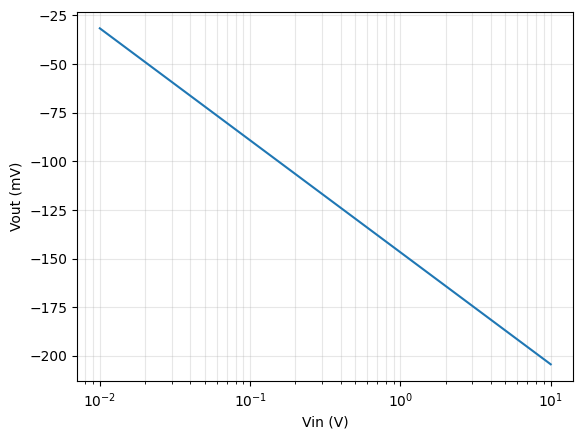

range of Vout for Vin 0.1 V ... 1 V: -89 ... -147 mV


In [5]:
def vlog(vin, r, ir): return -0.025*np.log(vin/(r*ir))
print(f"Prob 27: {vlog(1.5,47e3,60e-9)*1e3:.0f} mV;  Prob 26: {vlog(3,82e3,100e-9)*1e3:.0f} mV")
vin = np.logspace(-2, 1, 200); plt.semilogx(vin, vlog(vin, 47e3, 60e-9)*1e3); plt.xlabel("Vin (V)"); plt.ylabel("Vout (mV)"); plt.grid(alpha=.3, which="both"); plt.show()
print("range of Vout for Vin 0.1 V ... 1 V:", round(vlog(0.1,47e3,60e-9)*1e3), "...", round(vlog(1,47e3,60e-9)*1e3), "mV")

**Nhận xét:** Bài 27 cho -157 mV (sách: −157 mV); bài 26 cho -148 mV. Tín hiệu vào biến thiên 10 lần (0,1–1 V) chỉ làm ngõ ra đổi khoảng 58 mV: đó là nén dải động.